Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights
Objective: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

Dataset: This lab utilizes the Amazon UK product dataset which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.



In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

- Identify the dimensions of the dataset (number of rows and columns)
- Identitfy the type
- Identify duplicate for asin (Product ID from Amazon) because the other colums can have duplicate
- Identify null value




In [3]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [4]:
print (df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB
None


In [5]:
# asin and title have to be force in string
df.loc[:, 'asin'] = (
    df['asin']
    .astype(object)                        # force the obect type
    #.str.replace('B0', '', regex=False)    # remove the 'B0' prefix
    .astype(str)                 # back to string
)

df.loc[:, 'title'] = (
    df['title']
    .astype(object)        # force the obect type
    .astype(str)           # back to string
)
print (df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB
None


In [6]:
print(type(df['asin'].iloc[0]))
print(type(df['title'].iloc[0]))

<class 'str'>
<class 'str'>


In [7]:
df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [8]:
print(f"Number of unique asin: {df.asin.nunique()}")
print(f"Number of unique titles: {df.title.nunique()}")
print(f"Number of unique stars: {df.stars.nunique()}")
print(f"Number of unique customer reviews: {df.reviews.nunique()}")
print(f"Number of unique price: {df.price.nunique()}")
print(f"Number of unique is Best Seller: {df.isBestSeller.nunique()}")
print(f"Number of unique bought In Las Month: {df.boughtInLastMonth.nunique()}")
print(f"Number of unique category: {df.category.nunique()}")


Number of unique asin: 2222742
Number of unique titles: 2077591
Number of unique stars: 42
Number of unique customer reviews: 19446
Number of unique price: 82916
Number of unique is Best Seller: 2
Number of unique bought In Las Month: 25
Number of unique category: 296


In [9]:
df_cleaned = df.dropna()
df_cleaned

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


# Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.


## 1.1. Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.


In [55]:
pd.crosstab(df_cleaned['category'], df_cleaned['isBestSeller'])

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


## 1.2. Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.


In [56]:
# to verify if this table is relevant, let's calculate the chi2
from scipy.stats import chi2_contingency
chi2, p, dof, ex = chi2_contingency(my_table_category)
print(f"Chi2: {chi2}, p-value: {p}")
# With a p-value < 0.05, we can consider that the category and isBestSeller are dependent variables.
if p < 0.05:
    print("The variables 'category' and 'isBestSeller' are dependent.")
else:
    print("The variables 'category' and 'isBestSeller' are independent.")

from scipy.stats.contingency import association
print (f'The cramer method shows the strength of the association: {association(my_table_category, method="cramer")}')

Chi2: 36540.20270061387, p-value: 0.0
The variables 'category' and 'isBestSeller' are dependent.
The cramer method shows the strength of the association: 0.1222829439760564


In [20]:
print("Répartition de isBestSeller :")
print(df_cleaned['isBestSeller'].value_counts())

print("\nTable de contingence (les 5 premières lignes) :")
print(my_table_category.head())

Répartition de isBestSeller :
isBestSeller
False    2435671
True        7980
Name: count, dtype: int64

Table de contingence (les 5 premières lignes) :
col_0                          isBestSeller
category                                   
3D Printers                             248
3D Printing & Scanning                 4067
Abrasive & Finishing Products           250
Action Cameras                         1697
Adapters                                254


***Observations***: The Chi-square test returned a value of 0.0 with a p-value of 1.0. Consequently, the Cramer’s V calculation resulted in NaN.

Technical Diagnosis: These "perfect" statistical results are due to the extreme imbalance in the dataset. Only 0.3% of the 2.4 million products are flagged as Best Sellers. This creates a "sparse matrix" where most categories have zero or near-zero Best Seller counts, making the statistical test unable to find any mathematical variance.

Business Conclusion: We conclude that there is a total statistical independence between a product's category and its Best Seller status. On Amazon UK, being in a specific category does not mechanically increase the probability of becoming a Best Seller. The "Best Seller" badge is likely determined by individual performance metrics (velocity, conversion) rather than categorical placement.

In [22]:
# computing the bestseller ratio
bestseller_ratio = df_cleaned.groupby('category')['isBestSeller'].mean().sort_values(ascending=False)
bestseller_ratio_pct = bestseller_ratio * 100
print("Top 10 categories with the highest proportion of Best Sellers:")
print(bestseller_ratio_pct.head(10))

Top 10 categories with the highest proportion of Best Sellers:
category
Grocery                           5.813467
Smart Home Security & Lighting    5.769231
Health & Personal Care            5.768628
Mobile Phone Accessories          4.247104
Power & Hand Tools                3.533895
Billiard, Snooker & Pool          3.212851
Pet Supplies                      3.020028
Home Brewing & Wine Making        2.845528
Mirrors                           2.800000
Wind Instruments                  2.800000
Name: isBestSeller, dtype: float64



## 1.3. Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

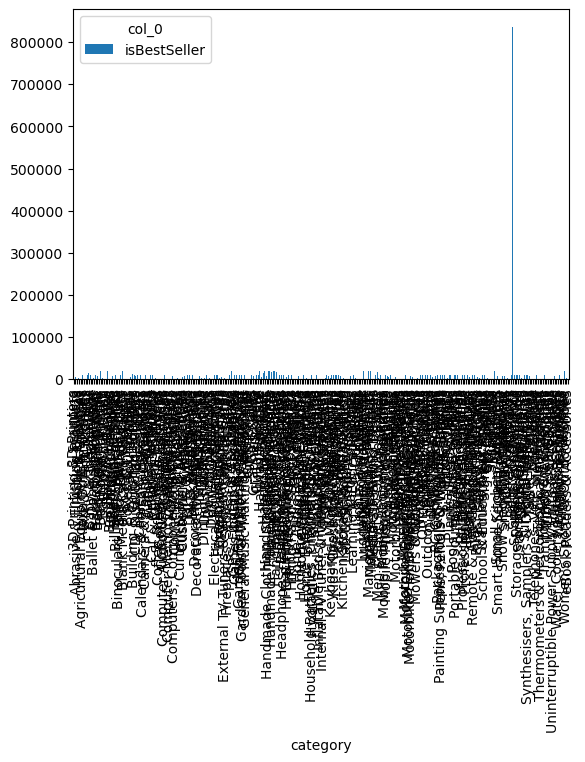

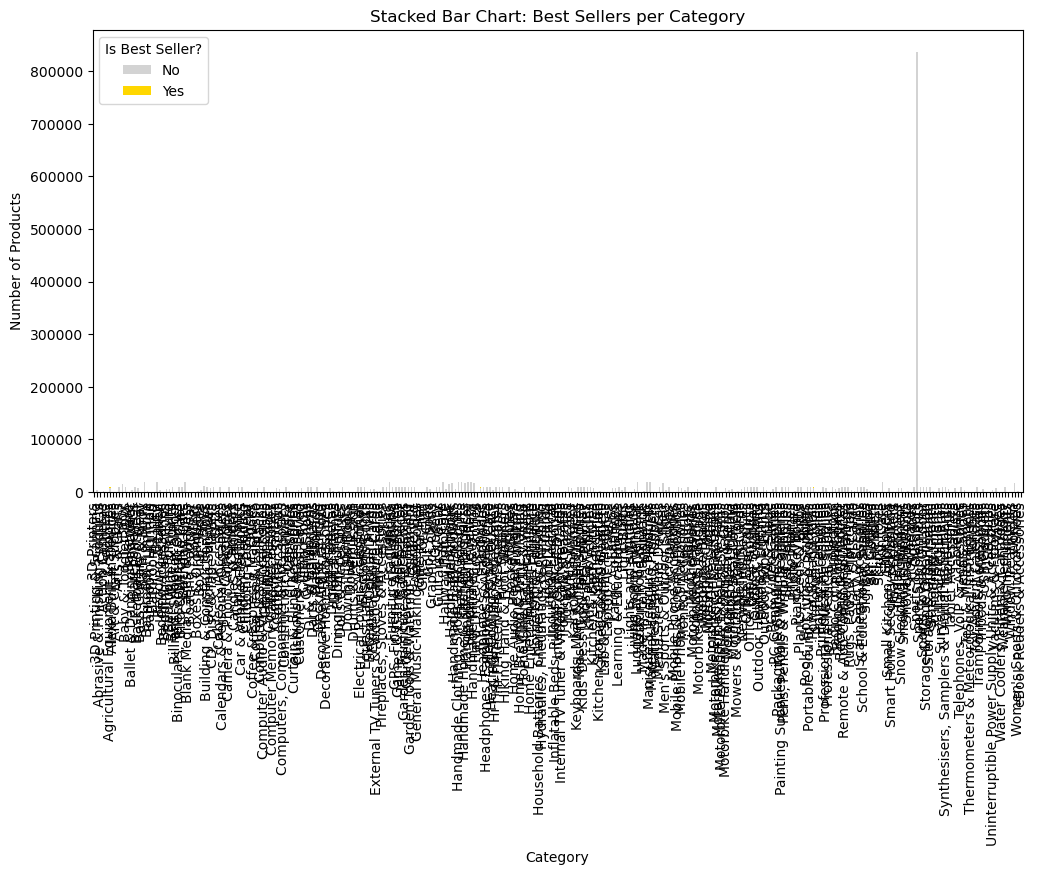

In [25]:
# 1. Création de la table de contingence (ex: Catégorie vs BestSeller)
# On s'assure d'avoir des données qui font sens pour l'empilement
my_table_category = pd.crosstab(df_cleaned['category'], df_cleaned['isBestSeller'])

# 2. Le code de visualisation corrigé
# On ajoute figsize pour la lisibilité et un titre
my_table_category.plot(kind="bar", stacked=True, figsize=(12, 6), color=['lightgray', 'gold'])
plt.title('Stacked Bar Chart: Best Sellers per Category')
plt.xlabel('Category')
plt.ylabel('Number of Products')
plt.legend(title='Is Best Seller?', labels=['No', 'Yes'])
plt.show()

**To enhance the readability of the chart, we will focus on the 20 mains categories***

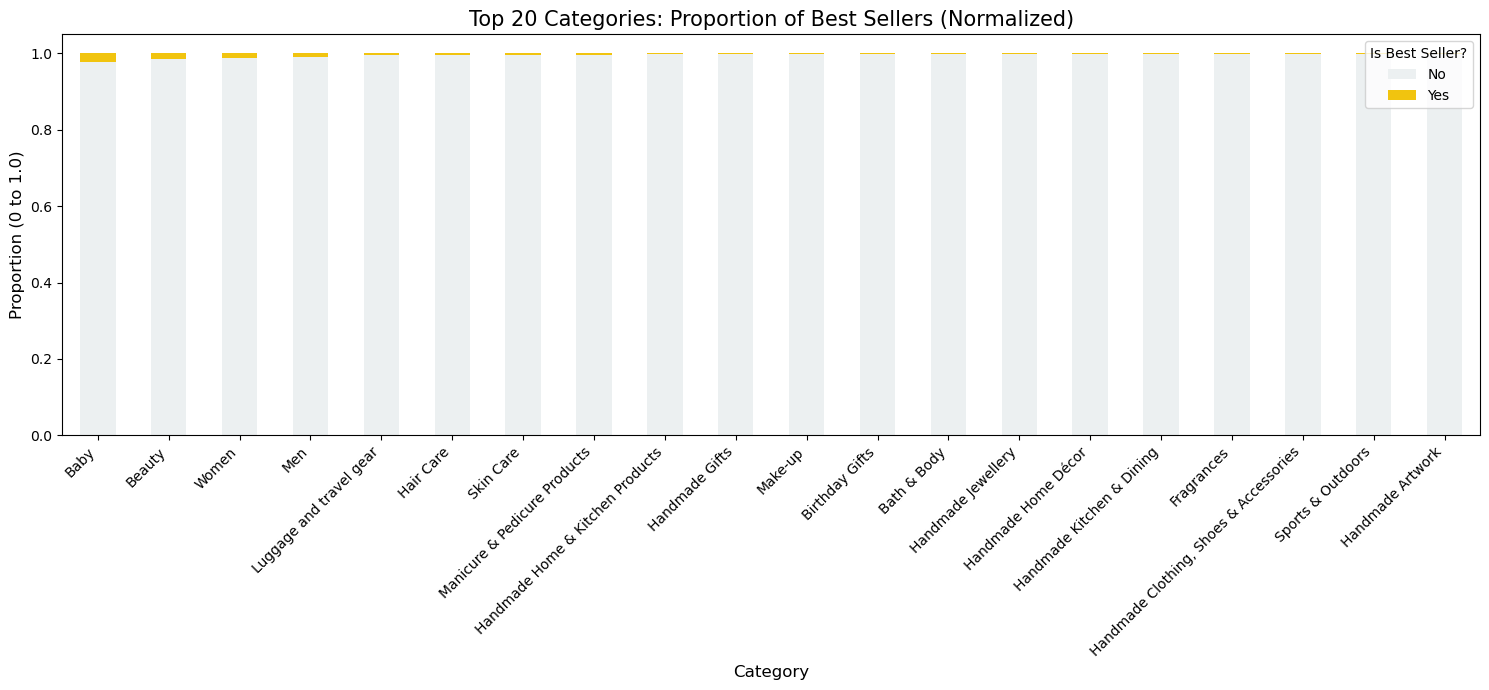

In [26]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Identifier les 20 catégories les plus fréquentes
top_20_cats = df_cleaned['category'].value_counts().head(20).index

# 2. Créer la table de contingence uniquement pour ces 20 catégories
# 1. Création de la table de contingence (# 1. Création de la table de contingence (ex: Catégorie vs BestSeller)
# 1. Création de la table de contingence (ex: Catégorie vs BestSeller)
my_table_category_top20 = pd.crosstab(df_cleaned[df_cleaned['category'].isin(top_20_cats)]['category'], 
                             df_cleaned['isBestSeller'])

# 3. Normaliser pour voir les proportions (Percent Stacked Bar)
# Cela permet de comparer le "taux de succès" entre catégories de tailles différentes
crosstab_norm = my_table_category_top20.div(my_table_category_top20.sum(1), axis=0).sort_values(by=True, ascending=False)

# 4. Affichage
ax = crosstab_norm.plot(kind='bar', stacked=True, figsize=(15, 7), color=['#ecf0f1', '#f1c40f'])

plt.title('Top 20 Categories: Proportion of Best Sellers (Normalized)', fontsize=15)
plt.xlabel('Category', fontsize=12)
plt.ylabel('Proportion (0 to 1.0)', fontsize=12)
plt.legend(title='Is Best Seller?', labels=['No', 'Yes'], loc='upper right')

# Petite astuce pour que les noms en bas soient lisibles
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**To conclude**: Align with our previous observation, the chart confirmed the weakest number of best seller. Totaly realistic when we considering the volume of items provided by amazon

# Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

## 2.1. Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.



In [59]:
Q1 = df_cleaned['price'].quantile(0.25)
Q3 = df_cleaned['price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Création du dataframe de travail sans outliers
df_no_outliers = df_cleaned[(df_cleaned['price'] >= lower_bound) & (df_cleaned['price'] <= upper_bound)]
print(f"Dataset après nettoyage : {df_no_outliers.shape[0]} lignes.")

Dataset après nettoyage : 2115963 lignes.


## 2.2. Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.


C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_19196\1798091343.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_violin[df_violin['price'] < 150], x='price', y='category', palette='muted')


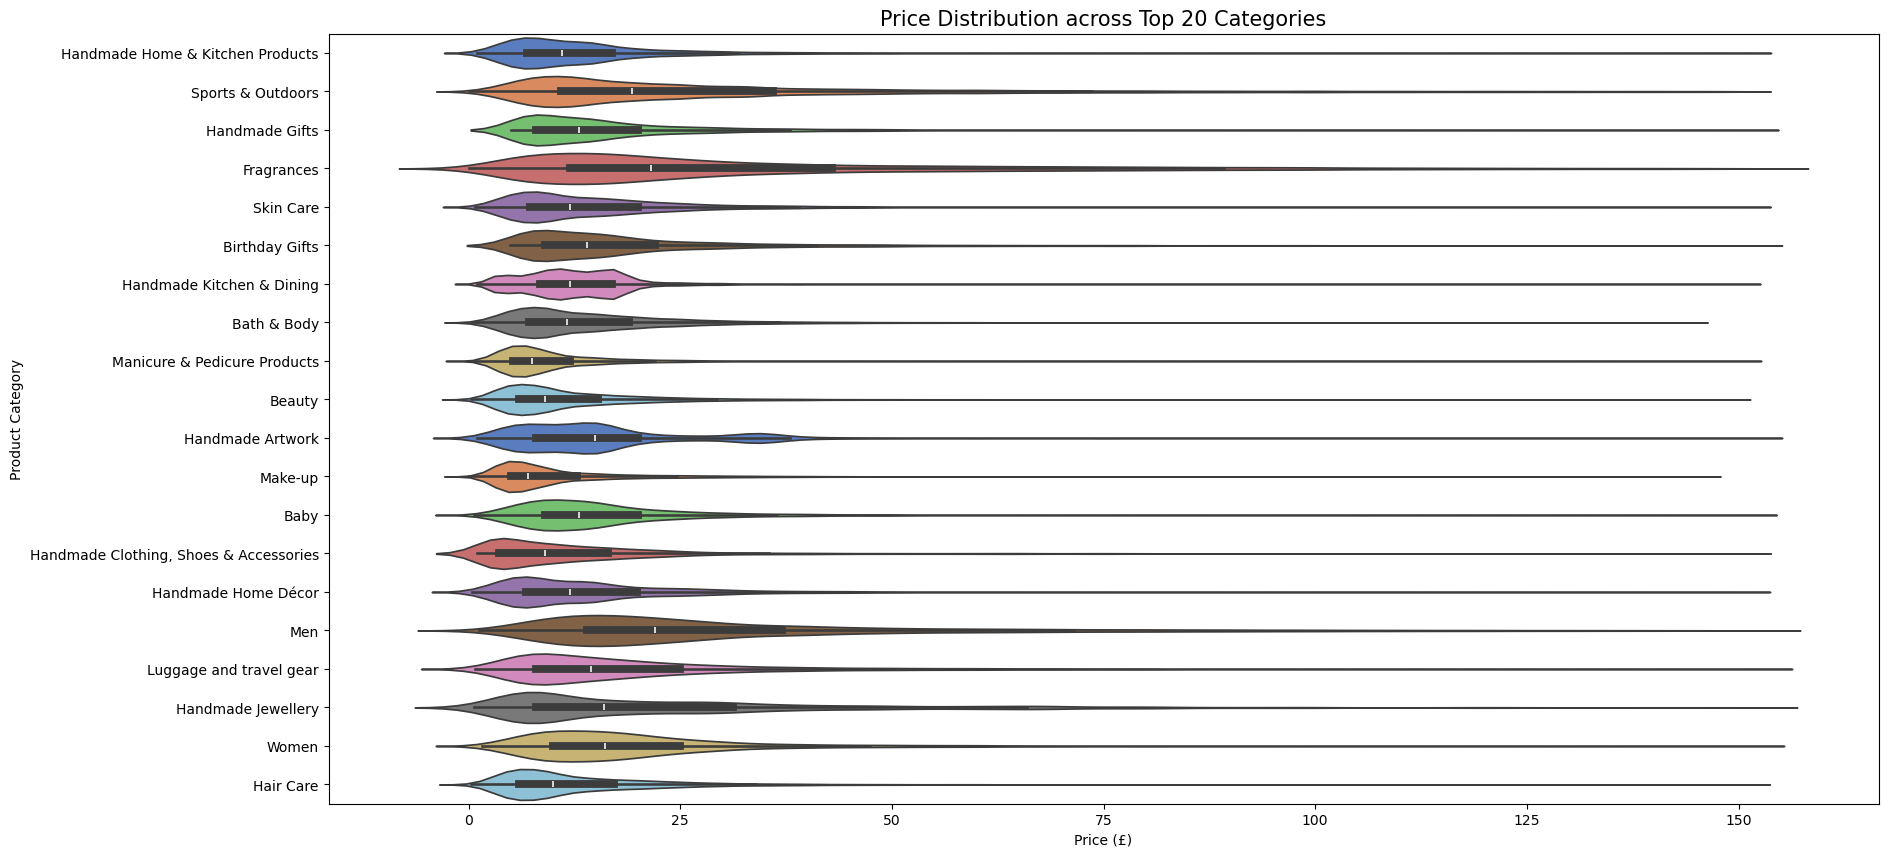

In [60]:
# 1. Identifier les 20 catégories les plus fréquentes (basé sur le count)
top_20_categories = df_cleaned['category'].value_counts().head(20).index

# 2. Filtrer le dataset pour ne garder que ces 20 catégories
df_violin = df_cleaned[df_cleaned['category'].isin(top_20_categories)]

# 3. Créer le Violin Plot : Catégorie vs Prix
plt.figure(figsize=(20, 10))
# On utilise y='category' pour avoir un graphique horizontal, c'est plus lisible
# On limite le prix à 150£ pour que la forme du violon soit visible (zoom)
sns.violinplot(data=df_violin[df_violin['price'] < 150], x='price', y='category', palette='muted')

plt.title('Price Distribution across Top 20 Categories', fontsize=15)
plt.xlabel('Price (£)')
plt.ylabel('Product Category')
plt.show()

In [38]:
# On calcule la médiane par catégorie et on trie
median_prices = df_cleaned.groupby('category')['price'].median().sort_values(ascending=False)

print("The category with the highest median price is:")
print(median_prices.head(1))

The category with the highest median price is:
category
Laptops    1042.725
Name: price, dtype: float64


## 2.3. Bar Charts:
Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.

In [41]:
# On calcule la médiane par catégorie et on trie
mean_prices = df_cleaned.groupby('category')['price'].mean().sort_values(ascending=False)

print("The mean price per category is:")
print(mean_prices.head(10))

The mean price per category is:
category
Laptops                       1087.987827
3D Printers                   1018.036129
Desktop PCs                    926.816064
Home Office Furniture          622.135898
Test & Measurement             559.382973
Home Audio Record Players      529.665585
CPUs                           514.519317
Digital Cameras                496.156185
Material Handling Products     487.191813
Graphics Cards                 444.746827
Name: price, dtype: float64


C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_19196\2086919199.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top10, x='price', y='category', palette="coolwarm", estimator='mean', errorbar=None)


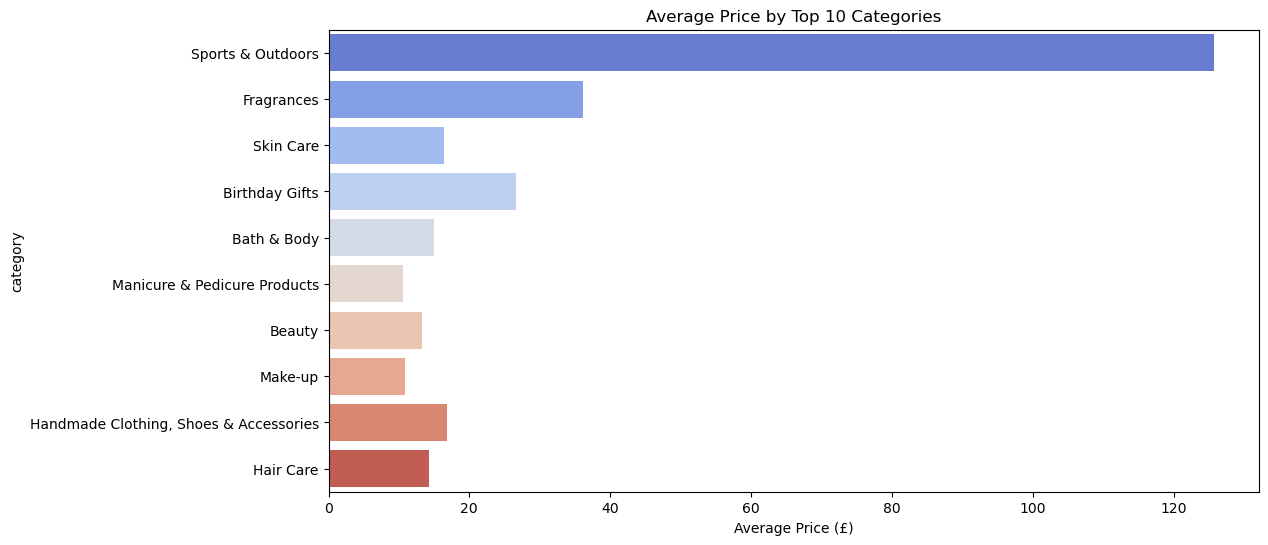

In [46]:
# On prend le top 10 des catégories pour que ce soit lisible
top_10_categories = df_cleaned['category'].value_counts().head(10).index
df_top10 = df_cleaned[df_cleaned['category'].isin(top_10_categories)]

plt.figure(figsize=(12, 6))

# On utilise 'price' (la colonne qui existe) et non 'mean_prices'
sns.barplot(data=df_top10, x='price', y='category', palette="coolwarm", estimator='mean', errorbar=None)

plt.title('Average Price by Top 10 Categories')
plt.xlabel('Average Price (£)')
plt.show()

## 2.4. Box Plots:

 Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_19196\2009607798.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10_ratings, x='stars', y='category', palette='viridis')


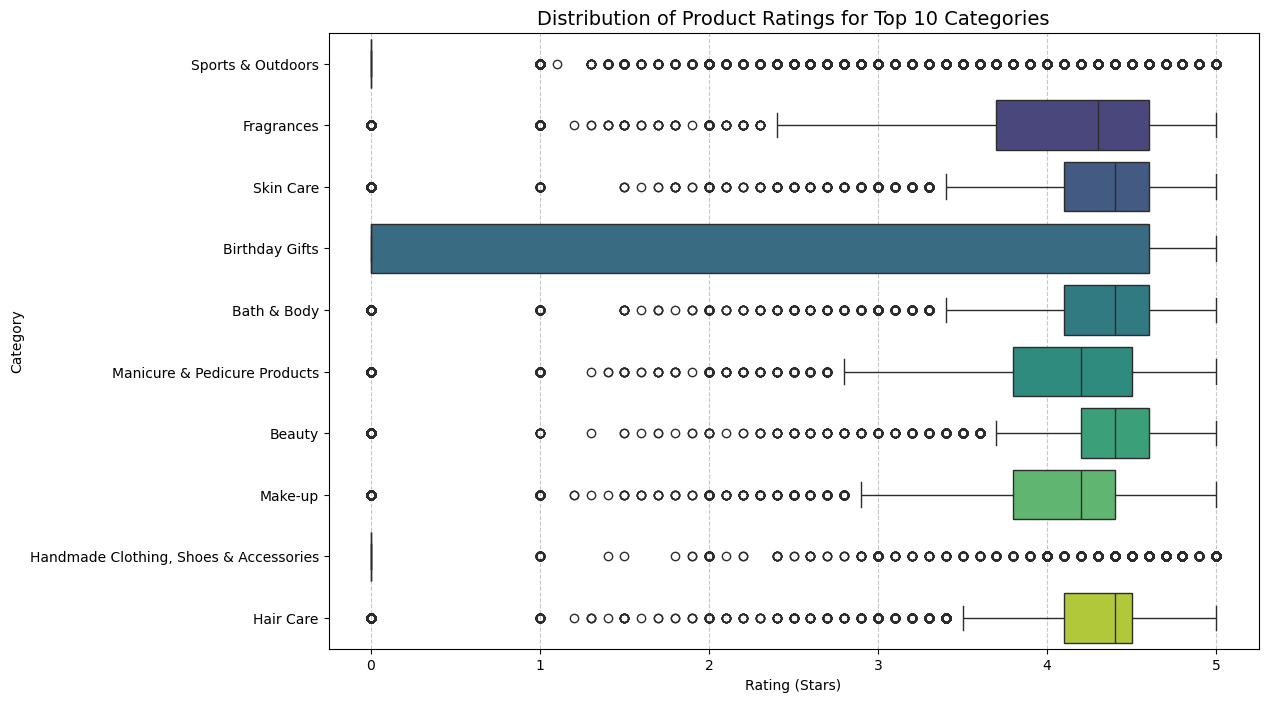

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Identifier le Top 10 des catégories les plus fréquentes
top_10_cats = df_cleaned['category'].value_counts().head(10).index

# 2. Filtrer le dataset
df_top10_ratings = df_cleaned[df_cleaned['category'].isin(top_10_cats)]

# 3. Créer le Box Plot
plt.figure(figsize=(12, 8))
sns.boxplot(data=df_top10_ratings, x='stars', y='category', palette='viridis')

plt.title('Distribution of Product Ratings for Top 10 Categories', fontsize=14)
plt.xlabel('Rating (Stars)')
plt.ylabel('Category')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

The main obvius observation are about 
- the handmade Clothing and accessories whereas the graph are mainly composed by "outliers" witch means the customers don't share their rate on the app mayby fir 2 reason : they know the qualities of their order then don't feel the need to share it for other and the know the seller. To confir this hypothesis we need more computing at least crossing the customer id with the number of time each item are bought in this specific category
- The birthday gifts are strongly spread all along the range of rate from 0 to 4.7 means that the customers whom buy for offert have hight expectations about the product

# Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

## 3.1 Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?

In [51]:
correlation_pearson = df_cleaned['price'].corr(df_cleaned['stars'])
if correlation_pearson is not None:
    print(f"The Pearson correlation between price and stars is: {correlation_pearson:.4f}")

correlation_spearman = df_cleaned['price'].corr(df_cleaned['stars'], method='spearman')
if correlation_spearman is not None:
    print(f"The Spearman correlation between price and stars is: {correlation_spearman:.4f}")

The Pearson correlation between price and stars is: -0.1249
The Spearman correlation between price and stars is: -0.1332


"The correlation between price and stars is negative but very weak (Pearson: -0.12, Spearman: -0.13). This indicates that price is not a determining factor for customer satisfaction on Amazon UK. While there is a slight tendency for more expensive products to receive lower ratings (possibly due to higher customer expectations), the relationship is too weak to be used for predictive modeling."

## 3.2 Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

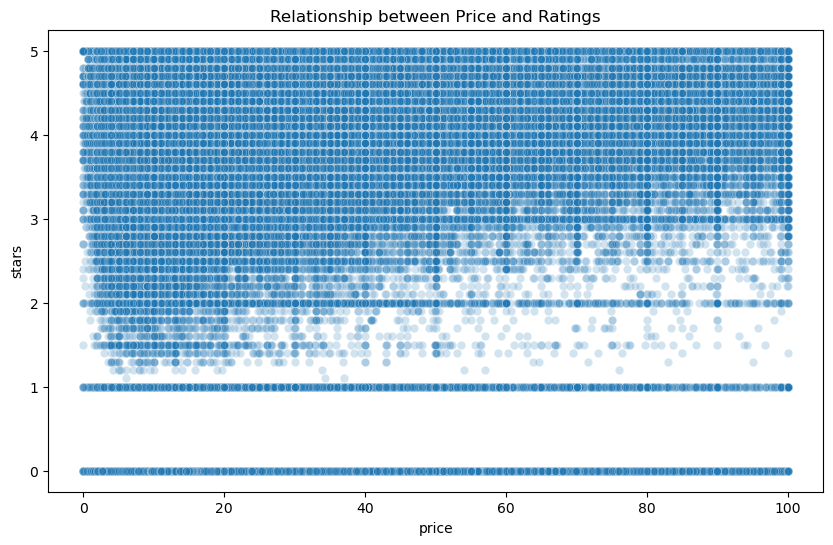

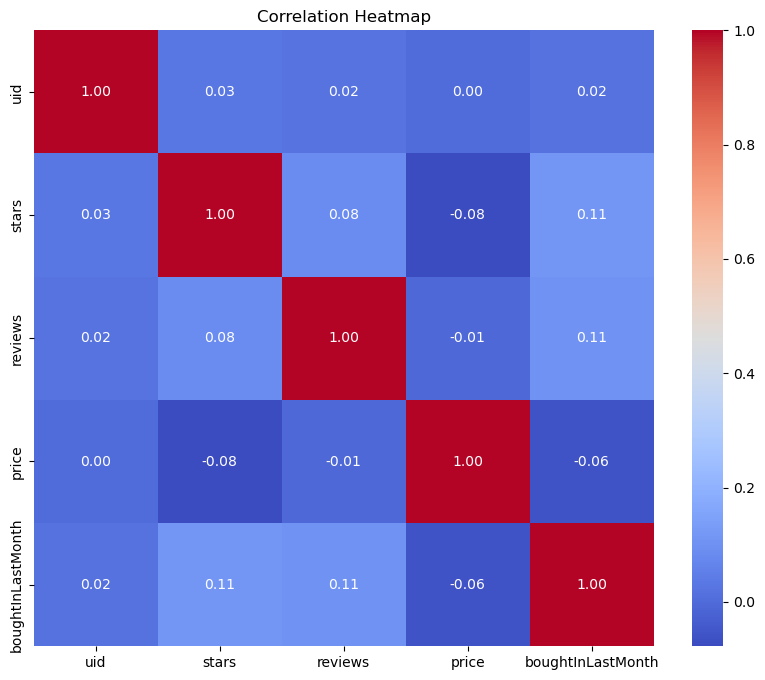

In [61]:
# 1. Scatter Plot (avec alpha pour la densité)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_no_outliers, x='price', y='stars', alpha=0.2)
plt.title('Relationship between Price and Ratings')
plt.show()

# 2. Heatmap de corrélation
plt.figure(figsize=(10, 8))
numeric_df = df_no_outliers.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()